## MNIST Handwritten Digits Dataset

#### Importing Libraries

In [1]:
import numpy as np
import matplotlib.pyplot as plt

#### Loading the MNIST Dataset

In [42]:
x_train = np.loadtxt("x_train.txt")
y_train = np.loadtxt("y_train.txt")
x_test = np.loadtxt("x_test.txt")
y_test = np.loadtxt("y_test.txt")

In [43]:
x_train

array([[0., 0., 0., ..., 0., 0., 0.],
       [0., 0., 0., ..., 0., 0., 0.],
       [0., 0., 0., ..., 0., 0., 0.],
       ...,
       [0., 0., 0., ..., 0., 0., 0.],
       [0., 0., 0., ..., 0., 0., 0.],
       [0., 0., 0., ..., 0., 0., 0.]])

In [44]:
y_train

array([5., 0., 4., ..., 5., 6., 8.])

In [45]:
x_test

array([[0., 0., 0., ..., 0., 0., 0.],
       [0., 0., 0., ..., 0., 0., 0.],
       [0., 0., 0., ..., 0., 0., 0.],
       ...,
       [0., 0., 0., ..., 0., 0., 0.],
       [0., 0., 0., ..., 0., 0., 0.],
       [0., 0., 0., ..., 0., 0., 0.]])

In [46]:
y_test

array([7., 2., 1., ..., 4., 5., 6.])

#### Checking the number of unique values in y data

In [47]:
np.unique(y_train)

array([0., 1., 2., 3., 4., 5., 6., 7., 8., 9.])

In [48]:
np.unique(y_test)

array([0., 1., 2., 3., 4., 5., 6., 7., 8., 9.])

#### Checking the data type & shape of the data

In [49]:
type(x_train), type(y_train)

(numpy.ndarray, numpy.ndarray)

In [50]:
type(x_test), type(y_test)

(numpy.ndarray, numpy.ndarray)

In [51]:
x_train.shape, y_train.shape

((60000, 784), (60000,))

In [52]:
x_test.shape, y_test.shape

((10000, 784), (10000,))

#### Reshaping the images - height x width = 28 x 28

In [55]:
x_train = x_train.reshape(60000, 28, 28)
x_test = x_test.reshape(10000, 28, 28)

In [56]:
x_train.shape

(60000, 28, 28)

In [57]:
x_test.shape

(10000, 28, 28)

#### Display MNIST Images

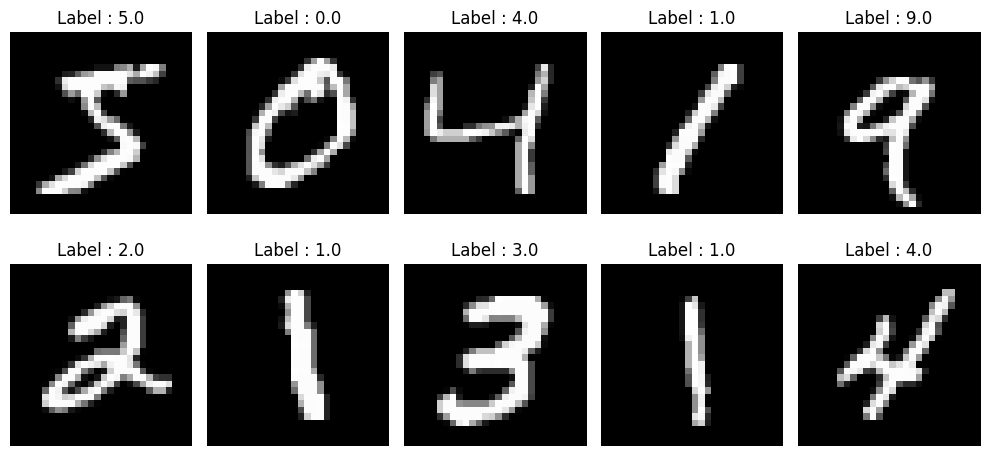

In [58]:
plt.figure(figsize=(10,5))

for i in range(10):
    plt.subplot(2,5,i+1)
    plt.imshow(x_train[i], cmap='gray')
    plt.title(f"Label : {y_train[i]}")
    plt.axis('off')

plt.tight_layout()
plt.show()

#### Normalize Pixel Values
- Converting pixel values from: 0-255  --->  0-1

In [59]:
print("Before Normalization")
print("Minimum Value :", x_train.min())
print("Maximum Value :", x_train.max())

Before Normalization
Minimum Value : 0.0
Maximum Value : 255.0


In [60]:
x_train = x_train / 255.0
x_test = x_test / 255.0

In [61]:
print("After Normalization")
print("Minimum Value :", x_train.min())
print("Maximum Value :", x_train.max())

After Normalization
Minimum Value : 0.0
Maximum Value : 1.0


#### Flattening Images

In [62]:
x_train_flat = x_train.reshape(60000, 784)
x_test_flat = x_test.reshape(10000, 784)

In [63]:
x_train_flat.shape, x_test_flat.shape

((60000, 784), (10000, 784))

In [65]:
len(x_train_flat[0])

784

#### Model Training

In [24]:
from sklearn.neighbors import KNeighborsClassifier

In [25]:
model = KNeighborsClassifier(n_neighbors=5)

In [27]:
model.fit(x_train_flat, y_train)

KNeighborsClassifier()

#### Model Evaluation

In [28]:
train_score = model.score(x_train_flat, y_train)
test_score = model.score(x_test_flat, y_test)

In [29]:
print(f'Training Score: {train_score}')
print(f'Test Score: {test_score}')

Training Score: 0.9819166666666667
Test Score: 0.9688


In [34]:
y_pred = model.predict(x_test_flat)

In [35]:
y_pred

array([7., 2., 1., ..., 4., 5., 6.])

In [36]:
y_test

array([7., 2., 1., ..., 4., 5., 6.])

### Trying Logistic Regression 

In [37]:
from sklearn.linear_model import LogisticRegression

In [38]:
model2 = LogisticRegression()

In [39]:
model2.fit(x_train_flat, y_train)

c:\Users\Maisara Waseem\AppData\Local\Programs\Python\Python310\lib\site-packages\sklearn\linear_model\_logistic.py:465: ConvergenceWarning: lbfgs failed to converge (status=1):
STOP: TOTAL NO. of ITERATIONS REACHED LIMIT.

Increase the number of iterations (max_iter) or scale the data as shown in:
    https://scikit-learn.org/stable/modules/preprocessing.html
Please also refer to the documentation for alternative solver options:
    https://scikit-learn.org/stable/modules/linear_model.html#logistic-regression
  n_iter_i = _check_optimize_result(


LogisticRegression()

In [40]:
train_score2 = model2.score(x_train_flat, y_train)
test_score2 = model2.score(x_test_flat, y_test)

In [41]:
print(f'Training Score: {train_score2}')
print(f'Test Score: {test_score2}')

Training Score: 0.93505
Test Score: 0.9258
